# بررسی ریسک در زمان تأیید سفارش

هدف این تحلیل شناسایی سفارش‌هایی است که بعداً نظر منفی می‌گیرند. پس از اجرای خط لوله، خروجی‌های این دفترچه نشان می‌دهد در زمان تأیید سفارش چه اطلاعاتی در دسترس بوده و نتایج در طول زمان چگونه تغییر کرده‌اند.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-darkgrid")
root = Path("part4") if Path("part4/capstone").is_dir() else Path(".")
out = root / "artifacts"

def read_result(name):
    return json.loads((out / name).read_text(encoding="utf-8"))

if not (out / "evaluation.json").is_file():
    raw_dir = os.environ.get("FTI_CAPSTONE_RAW_DIR")
    if not raw_dir:
        raise FileNotFoundError("Build the artifacts or configure the notebook build as described in the README.")
    from capstone.runner import main

    main(["build", "--raw-dir", raw_dir, "--output", str(out)])
results = read_result("evaluation.json")
winner = results["model_selected"]
metrics = results["metrics"]


## اطلاعات در دسترس هنگام تصمیم

برای هر ویژگی، زمان در دسترس بودن و دلیل استفاده را بررسی می‌کنیم. در دادهٔ عمومی، زمان مشاهدهٔ سبد خرید و پرداخت ثبت نشده است. پوشش این ویژگی‌ها جداگانه گزارش می‌شود.

In [2]:
display(Markdown((root / "feature_audit.md").read_text(encoding="utf-8")))
print(f"Timestamped checkout coverage: {results['snapshot_coverage']:.1%}")

# What could the team know at approval?

| Column | First available | Evidence and hypothesis |
|---|---|---|
| approval_weekday | Approval event | Olist purchase or approval timestamp. Weekly differences in processing. |
| approval_month | Approval event | Olist purchase or approval timestamp. Seasonal pressure. |
| approval_hour | Approval event | Olist purchase or approval timestamp. Shift staffing. |
| approval_lag_hours | Approval event | Olist purchase or approval timestamp. Waiting for approval may frustrate buyers. |
| purchase_hour | Purchase event | Olist purchase or approval timestamp. Purchasing time may reflect different service windows. |
| purchase_weekday | Purchase event | Olist purchase or approval timestamp. Weekend purchases can wait for working days. |
| is_weekend | Approval event | Olist purchase or approval timestamp. Weekend staffing may affect handling. |
| is_public_holiday | Published holiday calendar | Brazil national holiday calendar. Historical corrections are possible. Holiday staffing may slow service. |
| customer_state | Checkout customer record | Order-specific customer ID links to the checkout address. Olist has no address edit log, so this assumes checkout geography is stable. Regional service differences. |
| customer_zip_region | Checkout customer record | Order-specific customer ID links to the checkout address. Olist has no address edit log, so this assumes checkout geography is stable. Regional delivery coverage. |
| prior_day_shipments | End of the previous calendar day | SQL counts only dated events one day strictly before approval. Missing days contribute zero. Recent handoff volume proxies warehouse load. |
| prior_day_deliveries | End of the previous calendar day | SQL counts only dated events one day strictly before approval. Missing days contribute zero. Recent delivery volume proxies network load. |
| prior_day_replies | End of the previous calendar day | SQL counts only dated events one day strictly before approval. Missing days contribute zero. Recent feedback volume proxies service activity. |
| prior_day_negatives | End of the previous calendar day | SQL counts only dated events one day strictly before approval. Missing days contribute zero. Recent negative feedback may flag system-wide disruption. |
| snapshot_available | Checkout snapshot observed at or before approval | A timestamped capture distinguishes observed zeros from missing history. |
| seller_count | Checkout snapshot observed at or before approval | Distinct sellers in the captured basket test coordination burden. |
| product_count | Checkout snapshot observed at or before approval | Distinct products in the captured basket test packing complexity. |
| observed_payment_value | Checkout snapshot observed at or before approval | Captured payment total tests order-value effects. |
| interstate_shipping | Checkout snapshot observed at or before approval | Captured seller and customer states test cross-state shipping risk. |

The leaky comparison deliberately uses delivery duration, carrier handoff duration and final delivery status. Each is only known after approval. No current-order review enters production. Distinct item sellers, catalog measurements and payment totals have no first-seen timestamps in the public export. They are excluded from the retrospective model. An approval-time capture of the basket, catalog and payment authorizations would permit a broader model.


Timestamped checkout coverage: 0.0%


## تعداد سفارش‌ها و نظرها در هر ماه

سقف تماس برای همهٔ سفارش‌های تأییدشده محاسبه می‌شود. یادآوری را فقط روی نظرهای منفی ثبت‌شده می‌سنجیم. در ماه‌های کم‌حجم، ابتدا تعداد تماس‌های مجاز و نظرهای منفی را ببینید.

,eligible_orders,total_flagged,reviewed,negative_reviews,recall,approval_delay_recall
2018-05,7066,706,7028,841,0.126040,0.116528
2018-06,6164,616,6139,660,0.116667,0.095455
2018-07,6176,617,6130,672,0.107143,0.086310
2018-08,6620,662,6594,704,0.139205,0.102273
2018-09,1,0,1,1,0.000000,0.000000


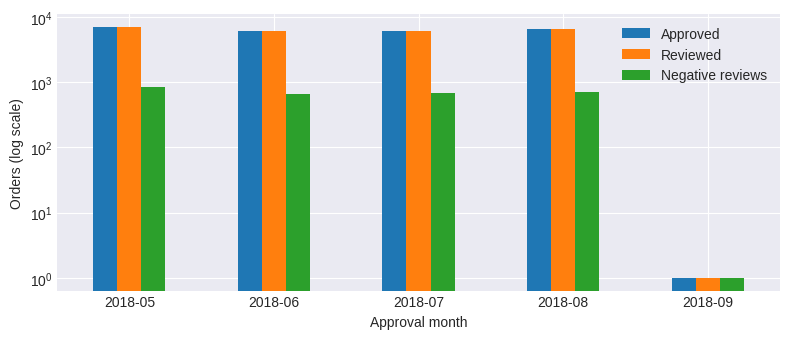

In [3]:
monthly = pd.DataFrame.from_dict(results["monthly"], orient="index")
columns = ["eligible_orders", "total_flagged", "n", "positives", "recall", "approval_delay_recall"]
display(monthly[columns].rename(columns={"n": "reviewed", "positives": "negative_reviews"}))
ax = monthly[["eligible_orders", "n", "positives"]].rename(
    columns={"eligible_orders": "Approved", "n": "Reviewed", "positives": "Negative reviews"}
).plot.bar(figsize=(8, 3.5), rot=0, logy=True)
ax.set(xlabel="Approval month", ylabel="Orders (log scale)")
plt.tight_layout()
plt.show()

## تغییر توزیع ویژگی‌ها و آزمایش‌های کنترل

اختلاف بین دورهٔ آموزش و آزمون را بررسی می‌کنیم. برای سنجش نقش تعطیلات، مدل منتخب را با پرچم ثابت دوباره آموزش می‌دهیم. آزمایش جداگانه‌ای نشان می‌دهد افزودن اطلاعاتی که پس از تأیید در دسترس است چقدر نتیجه را تغییر می‌دهد.

In [4]:
drift = pd.DataFrame(results["drift"]).T
display(drift["standardized_mean_shift"].dropna().sort_values(ascending=False).head(6).to_frame())
display(drift["total_variation_distance"].dropna().to_frame())
holiday_delta = metrics[winner]["0.1"]["recall"] - metrics["without_holiday"]["0.1"]["recall"]
print(f"Holiday flag: {100 * holiday_delta:+.2f} percentage points of recall")
print(f"Future information: {100 * results['leakage_recall_delta_at_10pct']:+.2f} percentage points of recall")

,standardized_mean_shift
prior_day_replies,0.769345
prior_day_deliveries,0.580377
prior_day_shipments,0.392518
approval_month,0.134031
is_weekend,0.078016
is_public_holiday,0.035184


,total_variation_distance
customer_state,0.057826
customer_zip_region,0.066387


Holiday flag: -0.14 percentage points of recall
Future information: +18.97 percentage points of recall
